# R3 · Fonctions — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r3_fonctions/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R3.1 à R3.12, R3.15 | Les exercices papier (vérification) | ✏️ 📈 🔗 | | |
| A | R3.21 | Tracer et lire les fonctions de référence | 📦 | ★ | 15 |
|  | R3.26 | Un graphique propre : titre, axes, légende | 🛠️ | ★ | 15 |
| B | R3.18 | La fonction affine qui passe par deux points · `affine_from_points` | 🔨 | ★ | 25 |
|  | R3.19 | Racines et sommet d'un polynôme du second degré · `quadratic_roots`, `quadratic_vertex` | 🔨 | ★★ | 40 |
|  | R3.22 | Faire varier a, b et c : déformer une parabole | 🎨 | ★★ | 20 |
|  | R3.24 | Combien de racines ? Le signe du discriminant sur une grille de paramètres | 🔬 | ★★ | 20 |
| C | R3.20 | Composer deux fonctions · `compose` | 🔨 | ★ | 25 |
|  | R3.23 | Prédire f∘g et g∘f pour « valeur absolue » et « moins 3 » | 🔮 | ★ | 10 |
|  | R3.25 | Chasse à l'erreur : composition, réciproque et racines | 🐛 | ★★ | 20 |
|  | R3.17 | Évaluer un polynôme par Horner · `polyval` | 🔨 | ★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : images, antécédents, lecture graphique, droites, second degré, variations, composées, réciproques, Horner.
- Écrire les cinq fonctions de `mymath/functions.py` et les tester.
- Tracer des fonctions avec NumPy, déformer des paraboles, prédire des composées.

**Rappel express.** Pente $m = \frac{y_2 - y_1}{x_2 - x_1}$, $c = y_1 - m x_1$ ; $ax^2 + bx + c = a(x - \alpha)^2 + \beta$ avec $\alpha = -\frac{b}{2a}$ ; $\Delta = b^2 - 4ac$ et racines $\frac{-b \pm \sqrt{\Delta}}{2a}$ ; $(f \circ g)(x) = f(g(x))$, $g$ d'abord ; $f^{-1}(f(x)) = x$.

## Partie 0 · Vérifier tes exercices papier (✏️ R3.1 à R3.12, 📈 R3.2, 🔗 R3.15)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un nombre avec un point décimal, `-1.5` ; une fraction exacte entre guillemets, `"5/7"` ;
- une liste de coefficients, du plus haut degré au terme constant, zéros compris : `[2, 0, -5]` pour $2x^2 - 5$ ;
- une liste de valeurs (solutions, antécédents, racines) dans l'ordre que tu veux, la liste vide s'il n'y en a aucune ; une fraction s'y écrit comme un calcul : `[-2/7, 6]` ;
- un intervalle entre guillemets, `"]-1 ; 4]"` ou `"[0 ; +oo["`, une réunion avec un U ;
- une fonction affine par la liste `[m, c]`, une forme canonique par `[a, alpha, beta]` ;
- vrai ou faux par `True` ou `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
from fractions import Fraction

**Ex R3.1 — Images, antécédents et ensemble de définition**

In [3]:
wbm.record("R3.1a", 3 * (-2) ** 2 - (-2) - 4, mistakes={"le carré d'un nombre négatif est positif : garde les parenthèses autour de −2": -14, "−x avec x = −2 donne +2": 6})
wbm.record("R3.1b", (2 * Fraction(1, 2) + 1) / (Fraction(1, 2) - 3), kind="fraction", mistakes={"le dénominateur 1/2 − 3 est négatif": "4/5"})
wbm.record("R3.1c", [-3, 3], ordered=False, mistakes={"un carré égal à un nombre positif : deux solutions opposées": [3], "un antécédent se cherche en résolvant h(x) = 10, pas en calculant h(10)": [101]})
wbm.record("R3.1d", [], ordered=False, mistakes={"un carré n'est jamais négatif : regarde ce que donne h(x) = −3": [-2, 2]})
wbm.record("R3.1e", 3.0, decimals=2, mistakes={"un antécédent se cherche en résolvant k(x) = 7, pas en calculant k(7)": 23.0, "pour isoler 4x, ajoute 5 aux deux membres": 0.5})
wbm.record("R3.1f", "]-oo ; 4[ U ]4 ; +oo[", kind="interval", mistakes={"x − 4 s'annule pour la valeur qui le rend nul, avec son signe": "]-oo ; -4[ U ]-4 ; +oo[", "on n'exclut qu'une seule valeur : celle qui annule le dénominateur": "]4 ; +oo["})
wbm.record("R3.1g", "]-oo ; 3]", kind="interval", mistakes={"6 − 2x ≥ 0 : en divisant par −2, le sens change": "[3 ; +oo[", "la racine carrée de 0 existe : la borne est incluse": "]-oo ; 3["})
wbm.record("R3.1h", "[-2 ; 1[ U ]1 ; +oo[", kind="interval", mistakes={"il faut les deux conditions : la racine et le dénominateur": "[-2 ; +oo[", "la racine carrée de 0 existe : la borne de gauche est incluse": "]-2 ; 1[ U ]1 ; +oo["})

WBM_ANSWER {"hash": "7c158407b4f9290cd47c1a69495fceca5196843b19e22f95066a75334ce10157", "id": "R3.1a", "kind": "int", "magnitude": 1, "mistakes": {"b86ac6c78d3ee47bbfbb4ff74946688810ff7cffb4a9070e8a24cc1c445c851d": "−x avec x = −2 donne +2", "e1a2cbc0593d00fdc25174d57d7dab328b9afbf1626246c1cea614f08bcc30c1": "le carré d'un nombre négatif est positif : garde les parenthèses autour de −2"}, "sign": 1}
📝 Ex R3.1a : réponse enregistrée (int).


WBM_ANSWER {"hash": "e16798eb1480770173fc83d8cfccf04b8c2ab93ce7b5b3eff3d6cc7900e16ff3", "id": "R3.1b", "kind": "fraction", "mistakes": {"758cfa51964ccc5ed06755207b92b0a1fcc71be2e75e1dd42e13737369593131": "le dénominateur 1/2 − 3 est négatif"}, "sign": -1}
📝 Ex R3.1b : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "5f3829384b7ef22e28f7dad2534b24a9d5c49ee94cf3a5f166fe67857e095a06", "id": "R3.1c", "kind": "set", "mistakes": {"8a45579c17302b357103367dbeb7602c5fa95a2dde4d7b9f87632eb8abd7503a": "un antécédent se cherche en résolvant h(x) = 10, pas en calculant h(10)", "b3924ab6bc674ce1d17042f9f2688c6538fe9ad35652b62575dc3306771eeed2": "un carré égal à un nombre positif : deux solutions opposées"}}
📝 Ex R3.1c : réponse enregistrée (set).
WBM_ANSWER {"hash": "2165fd4b5f5ef5e9bbad0151b8806c840c35f1357ce7a65f61336f3cdec2d1fc", "id": "R3.1d", "kind": "set", "mistakes": {"a80456aa3b91ea52d1ab6c4a2a9c9596db100369b24810ec52d870242024eb7f": "un carré n'est jamais négatif : regarde ce que donne 

**Ex R3.2 — Lire des valeurs, des solutions et des variations sur un graphique**

In [4]:
wbm.record("R3.2a", 4)
wbm.record("R3.2b", 0)
wbm.record("R3.2c", [-3, -1, 4], ordered=False, mistakes={"trace toute la droite y = 2 : elle coupe la courbe trois fois": [-1, 4], "des antécédents sont des abscisses, lues sur l'axe horizontal": [2]})
wbm.record("R3.2d", [-4, 0, 3], ordered=False, mistakes={"regarde aussi les extrémités de la courbe et ses points anguleux": [0], "l'extrémité gauche de la courbe est aussi sur l'axe horizontal": [0, 3]})
wbm.record("R3.2e", 4, mistakes={"le maximum est une valeur de f, lue sur l'axe vertical, pas une abscisse": 5})
wbm.record("R3.2f", [-2, 5], ordered=False, mistakes={"le maximum est atteint deux fois : regarde aussi les extrémités": [-2], "ce sont des valeurs de x, lues sur l'axe horizontal": [4]})
wbm.record("R3.2g", "[1 ; 5]", kind="interval", mistakes={"croissante : la courbe monte quand on va de gauche à droite": "[-2 ; 1]", "la courbe monte sans s'arrêter sur deux segments de suite : ils forment un seul intervalle": "[3 ; 5]", "un intervalle de variation se donne avec ses bornes, fermé": "]1 ; 5["})
wbm.record("R3.2h", "[-3 ; -1] U [4 ; 5]", kind="interval", mistakes={"f(x) ≥ 2 garde aussi les points sur la droite y = 2 : bornes incluses": "]-3 ; -1[ U ]4 ; 5[", "≥ 2 : là où la courbe est au-dessus de la droite y = 2, pas en dessous": "]-1 ; 4["})

WBM_ANSWER {"hash": "4a4714a57af35550b1d3c7490ef6da26c48b769e9b8c46650650d4159c03f735", "id": "R3.2a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex R3.2a : réponse enregistrée (int).
WBM_ANSWER {"hash": "12c6ac95ff94e78668f65b09fb87e476615fa222d22885fb1adc24a5232bc6cb", "id": "R3.2b", "kind": "int", "magnitude": null, "sign": 0}
📝 Ex R3.2b : réponse enregistrée (int).
WBM_ANSWER {"hash": "f04ecd6a2d6d378dc889e15b369cd16ad9f566c4644d3ef0f1f333cb63d9883e", "id": "R3.2c", "kind": "set", "mistakes": {"ca4824e648d32ca19c3ce1eaba379bae73c81fea8396cfacdc4b5ceb14029c11": "des antécédents sont des abscisses, lues sur l'axe horizontal", "d73137ede63c8bef533b509700df0e88c71a2c74857bb3ab4ffbacacda29126e": "trace toute la droite y = 2 : elle coupe la courbe trois fois"}}
📝 Ex R3.2c : réponse enregistrée (set).
WBM_ANSWER {"hash": "3e3771320d0dbbdda6327f8ab7df8f9534daa0f01545e2cbbf52eb3f20c7fa06", "id": "R3.2d", "kind": "set", "mistakes": {"a86023bb86fba011edafef708a4f7c287b8c6a06472f1939980614101

**Ex R3.3 — La fonction affine qui passe par deux points**

In [5]:
wbm.record("R3.3a", [2.0, -3.0], decimals=3, mistakes={"la pente est Δy/Δx, pas Δx/Δy": [0.5, 0.0], "l'ordre demandé est [m, c] : la pente, puis l'ordonnée à l'origine": [-3.0, 2.0]})
wbm.record("R3.3b", [-2.0, 1.0], decimals=3, mistakes={"c = y − m·x : avec une pente négative, attention aux signes": [-2.0, -3.0], "l'ordre demandé est [m, c] : la pente, puis l'ordonnée à l'origine": [1.0, -2.0]})
wbm.record("R3.3c", [0.4, 4.0], decimals=3, mistakes={"la pente est Δy/Δx : la variation de y divisée par celle de x": [2.5, 4.0]})
wbm.record("R3.3d", Fraction(1, 2), kind="fraction", mistakes={"la racine annule la fonction : isole x avec son signe": "-1/2", "la racine est l'abscisse où la droite coupe l'axe horizontal, pas l'ordonnée à l'origine": 1})
wbm.record("R3.3e", 45, mistakes={"f est affine, pas proportionnelle : f(50) n'est pas 5 × f(10)": 125})
wbm.record("R3.3f", 2 * 4 - 3 == 5, mistakes={"calcule m × 4 + c avec les m et c de a, puis compare à 5": False})
wbm.record("R3.3g", [1.2, 5.0], decimals=3, mistakes={"l'ordre demandé est [m, c] : la pente, puis l'ordonnée à l'origine": [5.0, 1.2]})

WBM_ANSWER {"decimals": 3, "element_coarse": [["747ce51f63cab105c0daf2cbdf312c715360cac8092e11aae36424128028f701"], ["ec799402321fdd413e2b4dfc0232f7089072559207248c161e1e64da0c5161c7"]], "element_hashes": ["d5f7c7429cbcd1202e7b83cdfba9a0eb3f78675356d402b92a9734f9399a7b30", "a49c6689abde324a6d506479c722c0edd04b9048dc193d866ad1ad47e6411620"], "hash": "d5e3be8e776170cf83b614748d8e4600d99890756adccd884461ad08bb042f91", "id": "R3.3a", "kind": "array", "mistakes": {"1cdc0d745bdaca8ba0895dbf2563b038f9cbb364630951365fc1cafb204dc098": "l'ordre demandé est [m, c] : la pente, puis l'ordonnée à l'origine", "e77065c5e8c7ecc8ed9aeed0dc9cdbb04f19ec9029e33e788060293067681190": "la pente est Δy/Δx, pas Δx/Δy"}, "shape": [2]}
📝 Ex R3.3a : réponse enregistrée (array, 3 décimale(s)).
WBM_ANSWER {"decimals": 3, "element_coarse": [["7dd94e410843737bf77080215b65ee6cc87a261a4a917b0a83597bb7f9612339"], ["cc72eab8f5d830b00fb8141519f7536c4d20c33d587047fbec5fe49a09caba0b"]], "element_hashes": ["f54c1be16f2381d621

**Ex R3.4 — Ramener des données entre 0 et 1 avec une fonction affine (min-max)**

In [6]:
wbm.record("R3.4a", [0.01, -0.2], decimals=4, mistakes={"l'ordre demandé est [m, c] : la pente, puis l'ordonnée à l'origine": [-0.2, 0.01]})
wbm.record("R3.4b", Fraction(65 - 20, 100), kind="fraction", mistakes={"retire le minimum avant de diviser par l'étendue": "13/24"})
wbm.record("R3.4c", [100.0, 20.0], decimals=3, mistakes={"la réciproque défait N : multiplie par l'étendue, puis ajoute le minimum": [100.0, -20.0], "l'ordre demandé est [m, c] : la pente, puis l'ordonnée à l'origine": [20.0, 100.0]})
wbm.record("R3.4d", 100, mistakes={"multiplie par l'étendue, puis ajoute le minimum": 80})
wbm.record("R3.4e", [0.1, -2.0], decimals=3, mistakes={"10 × N multiplie les deux coefficients par 10": [0.1, -0.2]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["30dde6045f376ff0b4d5ac5ea724b25cd04b25513dfde7b2977a8c6ba4148b37"], ["308ab60d0e6c04a69e6939aed72e4eb31a6c2d43b2c768637624891a682505c1"]], "element_hashes": ["e45fc58fc044505d9738e36b9db9229dfeaa42a4b07337dfeb5779cd966b00b4", "6f5f553ba438c4328efc70d0594c68efd20ee490bfdf877135561a516aaca975"], "hash": "d73ae65a0335e4295ce8346b0aa9e4bce0909aa013530c429317f566ec557bd7", "id": "R3.4a", "kind": "array", "mistakes": {"55ba51c7bfe6b5f671ccee3938a29824e79ae238964eba230691ae266feed82d": "l'ordre demandé est [m, c] : la pente, puis l'ordonnée à l'origine"}, "shape": [2]}
📝 Ex R3.4a : réponse enregistrée (array, 4 décimale(s)).
WBM_ANSWER {"hash": "824ad0a7d3b928dfa4d06718b47cce1ce82d6af6d5cb25831a31822ebe628568", "id": "R3.4b", "kind": "fraction", "mistakes": {"eac68450f37eb8a6cbc3b550043062c315479fed8eaa53293c65307f48bd3beb": "retire le minimum avant de diviser par l'étendue"}, "sign": 1}
📝 Ex R3.4b : réponse enregistrée (fraction).
WBM_ANSWER {"

**Ex R3.5 — Variations et signe des fonctions de référence**

In [7]:
wbm.record("R3.5a", "]-oo ; 0]", kind="interval", mistakes={"le carré décroît à gauche de 0 et croît à droite": "[0 ; +oo[", "un intervalle de variation se donne avec ses bornes, fermé du côté de 0": "]-oo ; 0["})
wbm.record("R3.5b", "]-3 ; 3[", kind="interval", mistakes={"x² < 9 garde aussi des négatifs : essaie x = −2": "]-oo ; 3[", "l'inégalité est stricte : les bornes sont exclues": "[-3 ; 3]"})
wbm.record("R3.5c", "]0 ; 0.5[", kind="interval", mistakes={"1/x est négatif pour x < 0 : seuls des x positifs conviennent": "]-oo ; 0.5[", "l'inverse est décroissant sur ]0 ; +∞[ : il retourne l'ordre": "]0.5 ; +oo["})
wbm.record("R3.5d", "[0 ; 9]", kind="interval", mistakes={"√x n'est définie que pour x ≥ 0": "]-oo ; 9]", "√x ≤ 3 : élève au carré, ne prends pas une racine de plus": "[0 ; 3]"})
wbm.record("R3.5e", "]-oo ; -2] U [2 ; +oo[", kind="interval", mistakes={"|x| ≥ 2 : les points à distance au moins 2 de 0, donc à l'extérieur": "[-2 ; 2]", "l'inégalité est large : les bornes sont incluses": "]-oo ; -2[ U ]2 ; +oo["})
wbm.record("R3.5f", "[0 ; 4]", kind="interval", mistakes={"quand x parcourt l'intervalle, x passe par 0 : trace la courbe": "[1 ; 4]"})
wbm.record("R3.5g", 1 / -0.3 > 1 / -0.2, mistakes={"calcule les deux nombres, ou sers-toi du sens de variation de l'inverse sur les négatifs": False})

WBM_ANSWER {"hash": "26d013c08e4047493b4301992b5b98efeaaabbbe4750aca8e094a22ac745720e", "id": "R3.5a", "kind": "interval", "mistakes": {"e1b22e6000cfb59fb491f92868aaa9915d7c7e10d229ec13110986eb73220390": "un intervalle de variation se donne avec ses bornes, fermé du côté de 0", "f9e5479c90fdaea7e31ff596422f1183c29943db6fef4aa81a28435a1b1e5758": "le carré décroît à gauche de 0 et croît à droite"}}
📝 Ex R3.5a : réponse enregistrée (interval).
WBM_ANSWER {"hash": "f12e9b9a453afc384ec3e9efa171f3d9d4598bb0916efd21f94780e273485297", "id": "R3.5b", "kind": "interval", "mistakes": {"3cc3f052182ff1542f4d6cd8601c9c6e969ec7354f64bba1d324fb083171a65c": "x² < 9 garde aussi des négatifs : essaie x = −2", "4877cc446f4c1d7feebbc8c75f4ae9fec2f14d294521a47a1ff091bde7bd7154": "l'inégalité est stricte : les bornes sont exclues"}}
📝 Ex R3.5b : réponse enregistrée (interval).
WBM_ANSWER {"hash": "a04503060ba8e3cef34d593372c68859ea6ef2816a89589d4a134311489d3338", "id": "R3.5c", "kind": "interval", "mistakes"

**Ex R3.6 — Forme canonique et sommet d'une parabole**

In [8]:
wbm.record("R3.6a", [1, -3, -7], mistakes={"(x − α)² : α est l'opposé du nombre dans la parenthèse": [1, 3, -7], "le carré ajouté pour compléter doit être retiré": [1, -3, 2]})
wbm.record("R3.6b", [2, 3, -5], mistakes={"a est en facteur : le carré retiré est multiplié par a": [2, 3, 4], "(x − α)² : α est l'opposé du nombre dans la parenthèse": [2, -3, -5]})
wbm.record("R3.6c", [-1, 2, 5], mistakes={"avec a = −1, mets −1 en facteur et suis les signes": [-1, 2, -3], "a est le coefficient de x², avec son signe": [1, 2, 5]})
wbm.record("R3.6d", [-1, -5], mistakes={"α = −b/(2a) : attention au signe": [1, 7], "le carré d'un nombre négatif est positif": [-1, -11]})
wbm.record("R3.6e", [2, 8, 11], mistakes={"développe le carré, puis multiplie tout le carré développé par a": [2, 4, 7], "un sommet d'abscisse négative donne (x + …)² dans la forme canonique": [2, -8, 11]})
wbm.record("R3.6f", 2, mistakes={"(3 − 1)² est un carré : calcule-le avant de résoudre": 4})

WBM_ANSWER {"decimals": 0, "element_hashes": ["19d25cefb0c95e5fcc6070a94a4561ae00be9a76115f93dd7f9cb472aa664a84", "233d2909662ab37377399837ab4b480489ced1e4d4d5c481cd2da399979d0c3c", "f08e045f2550e2ca183c43d8a19ec399aa3b9cc5a67f0062981dfccd808b9ee1"], "hash": "c899eb17eb94391361b010e8b069b6e9b89713586e1024cce64b18b656412faf", "id": "R3.6a", "integer": true, "kind": "array", "mistakes": {"29b495bcf3015f7a61dd0980dcc996e18f6de33677ea6a53114d09b363665f85": "le carré ajouté pour compléter doit être retiré", "9498378afa9987a053cedcb43be377d9d955f900676634c139b7b9e17aed4850": "(x − α)² : α est l'opposé du nombre dans la parenthèse"}, "shape": [3]}
📝 Ex R3.6a : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"decimals": 0, "element_hashes": ["22c1fb9ccc83ac563cd8cec25823564621d35c2b665c84b101c0bd3da555d086", "37b4f2cfa2ee3f05f2c4e27f2eb08e3073c373c9993ea3c5c70094089663abb2", "50d4b5e1a7deeee5de49d20806bb3e279866d90e12ea2f1ab3486efff6c6d627"], "hash": "c045a52bf13768cdeafd72e91bff610cc4

**Ex R3.7 — Racines par le discriminant et factorisation**

In [9]:
wbm.record("R3.7a", (-5) ** 2 - 4 * 3 * (-2), mistakes={"b² avec b négatif : un carré est positif": -1, "−4ac avec c négatif : moins par moins donne plus": 1})
wbm.record("R3.7b", [-1 / 3, 2], ordered=False, decimals=8, mistakes={"−b avec b négatif donne un nombre positif": [-2, 1 / 3]})
wbm.record("R3.7c", [3, -1 / 3, 2], decimals=8, mistakes={"n'oublie pas le coefficient a devant le produit": [1, -1 / 3, 2], "x₁ < x₂ : la plus petite racine d'abord": [3, 2, -1 / 3]})
wbm.record("R3.7d", [3], ordered=False, mistakes={"(x − 3)² s'annule quand x − 3 = 0 : résous avec le bon signe": [-3]})
wbm.record("R3.7e", [], ordered=False, mistakes={"un discriminant négatif : pas de racine réelle": [-0.25]})
wbm.record("R3.7f", [-2, 4], ordered=False, mistakes={"avec a négatif, 2a est négatif : les signes changent": [2, -4]})
wbm.record("R3.7g", "]-1/3 ; 2[", kind="interval", mistakes={"a > 0 : le polynôme est négatif entre les racines, pas à l'extérieur": "]-oo ; -1/3[ U ]2 ; +oo[", "l'inégalité est stricte : les racines sont exclues": "[-1/3 ; 2]"})

WBM_ANSWER {"hash": "ef8a1a50d2e14619d2bd21a8548cc08267995d9e0e4686bbe420cea4167b9baf", "id": "R3.7a", "kind": "int", "magnitude": 1, "mistakes": {"8ef64251b5e44e5a1ec5e6725c4139511f1eff39b98d6fac2ab8dbf60a24f791": "−4ac avec c négatif : moins par moins donne plus", "9bfd5f755e89c37ad78d83865e7df828eb9c7dedefd4d7c3d1b9318e21cdd6a1": "b² avec b négatif : un carré est positif"}, "sign": 1}
📝 Ex R3.7a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 8, "hash": "4276bf5ca55dedf761c0bc654cab61cd517d1313460aeda9a1bcc8972569787a", "id": "R3.7b", "kind": "set", "mistakes": {"9586ef02acf3040d728ec4530857ffe6e2e11067fbe073c64b3ac40d565d82cc": "−b avec b négatif donne un nombre positif"}, "set_rounded": {"1": "ebdf353e978e2bd7db5e8d35fc0c9cfec1ae25d0c3d2f80ef2df459df8effa1d", "2": "b7a7b3f7ac8064230743dd811ad7b36c2999849df771096b986605830087e10d", "3": "c320ee0052a20ceadcbd13f881b1195f4c5595e3e65b5c625871848a3fd8e2fd", "4": "060cbd283e42f61b9a687ae9001c4686679b746ffc47265b6f3148580e774578", "

**Ex R3.8 — Trouver le maximum d'une aire ou d'un bénéfice**

In [10]:
wbm.record("R3.8a", 10 * (40 - 2 * 10), mistakes={"le grillage fait trois côtés : deux de longueur x et un de longueur 40 − 2x": 400, "le mur fait le quatrième côté : seuls trois côtés sont en grillage": 100, "on demande l'aire maximale, pas la valeur de x qui la donne": 10})
wbm.record("R3.8b", 10, mistakes={"on demande la valeur de x, pas l'aire": 200})
wbm.record("R3.8c", [5, 15], ordered=False, mistakes={"l'équation du second degré a deux solutions, de part et d'autre du sommet": [5], "il y a deux solutions : cherche l'autre": [15]})
wbm.record("R3.8d", 25, mistakes={"on demande le prix, pas la recette": 2500})
wbm.record("R3.8e", 25 * (200 - 4 * 25), mistakes={"on demande la recette, pas le prix": 25})

WBM_ANSWER {"hash": "4c4264999daabbea8938828474fc9423091d91c8e398c374e764c689d03f8460", "id": "R3.8a", "kind": "int", "magnitude": 2, "mistakes": {"211f86f1ec42318970fce86412b3834fadf744ac05d826c06985908536b0f378": "le mur fait le quatrième côté : seuls trois côtés sont en grillage", "8527891940cf4aeef46369b45c184d3553605b4c00c3e72059ef9af032666acc": "on demande l'aire maximale, pas la valeur de x qui la donne", "b6a8830c136cef9ae36d84ec2091cbdbd3f377cc73c42091f8226634cc39fa60": "le grillage fait trois côtés : deux de longueur x et un de longueur 40 − 2x"}, "sign": 1}
📝 Ex R3.8a : réponse enregistrée (int).
WBM_ANSWER {"hash": "aeb29fcb45baf3b6f81110ce7e33016d4d965744c83a89eecfb34bf17700e114", "id": "R3.8b", "kind": "int", "magnitude": 1, "mistakes": {"210431129be156820c819120cab22979377666871b9908396376460c0c014e4c": "on demande la valeur de x, pas l'aire"}, "sign": 1}
📝 Ex R3.8b : réponse enregistrée (int).
WBM_ANSWER {"hash": "a20f8d5d1c71737881730b54694993b2a853fac29b01dbfd34acc8fd

**Ex R3.9 — Composer deux fonctions dans les deux ordres**

In [11]:
wbm.record("R3.9a", (2 * 2**2 + 1) - 4, mistakes={"(f∘g)(2) : g d'abord, puis f": 9})
wbm.record("R3.9b", 2 * (2 - 4) ** 2 + 1, mistakes={"(g∘f)(2) : f d'abord, puis g": 5})
wbm.record("R3.9c", [2, 0, -3], mistakes={"(f∘g)(x) = f(g(x)) : on remplace x par g(x) dans f": [2, -16, 33]})
wbm.record("R3.9d", [2, -16, 33], mistakes={"(g∘f)(x) = g(f(x)) : on remplace x par f(x) dans g": [2, 0, -3], "(x − 4)² a un double produit": [2, 0, 33], "multiplie tout le carré développé par 2": [2, -8, 17], "le terme constant du carré développé est lui aussi multiplié par 2": [2, -16, 17]})
wbm.record("R3.9e", [1, -8], mistakes={"f∘f applique f deux fois, ce n'est pas f(x) × f(x)": [1, -8, 16]})
wbm.record("R3.9f", [-5, 4], mistakes={"l'ordre demandé est [m, c] : la pente, puis l'ordonnée à l'origine": [4, -5], "v(x) = 4 − 5x : la pente est le coefficient de x, avec son signe": [5, 4]})
wbm.record("R3.9g", [9 / 4], ordered=False, decimals=6)
wbm.record("R3.9h", [-3, 13], mistakes={"p∘q = p(q(x)) : q d'abord, puis p": [-3, 7]})

WBM_ANSWER {"hash": "60d968aa22dc47da886b1f5a7eb6effdc94f53eb2b169b3e97a9c45585e52cc8", "id": "R3.9a", "kind": "int", "magnitude": 0, "mistakes": {"f21c8061250b5dd4201d13c08295749c4b33c8ba90838bccabb8e7e66c8a02fa": "(f∘g)(2) : g d'abord, puis f"}, "sign": 1}
📝 Ex R3.9a : réponse enregistrée (int).
WBM_ANSWER {"hash": "aff61a2d5f19ec4e3ee41807154f3c2210a68eb004ef07830b648b3e5526c26e", "id": "R3.9b", "kind": "int", "magnitude": 0, "mistakes": {"0707cbe5e9015a118c135a9cffbe04b79634c5cb5dc3375f5edf0f2134ed7888": "(g∘f)(2) : f d'abord, puis g"}, "sign": 1}
📝 Ex R3.9b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["0617df6a8ed11d18d81c3a69671895118244931f47c75de921c0030b39cc463d", "6bf1aea938867bb09352fb5ab0a039dce77410204038af1339c8f74564c9ad87", "3c8a89d94505084c5f0746d79230f0a4435bb30d822e86c271c2fce27c4261bd"], "hash": "ddc633f3515da495fc78a7870c21334189e2cd33994bff050d1fbf5016d9d50e", "id": "R3.9c", "integer": true, "kind": "array", "mistakes": {"64cc34148889

**Ex R3.10 — Trouver une réciproque et son ensemble de définition**

In [12]:
wbm.record("R3.10a", [0.25, 0.75], decimals=4, mistakes={"pour isoler x, ajoute 3 puis divise par 4": [0.25, -0.75], "l'ordre demandé est [m, c] : la pente, puis l'ordonnée à l'origine": [0.75, 0.25]})
wbm.record("R3.10b", 3.0, decimals=4, mistakes={"f⁻¹(9) est l'antécédent de 9 par f, pas f(9)": 33.0, "f⁻¹ n'est pas 1/f : f⁻¹(9) est le nombre x tel que f(x) = 9": 1 / 33})
wbm.record("R3.10c", 1 + Fraction(2, 4), kind="fraction", mistakes={"g⁻¹(4) est le nombre x tel que g(x) = 4, pas g(4)": "2/3"})
wbm.record("R3.10d", "]-oo ; 0[ U ]0 ; +oo[", kind="interval", mistakes={"g⁻¹ est définie sur l'ensemble des valeurs prises par g, pas sur celui de g": "]-oo ; 1[ U ]1 ; +oo["})
wbm.record("R3.10e", "[3 ; +oo[", kind="interval", mistakes={"h⁻¹ est définie sur l'ensemble des valeurs prises par h": "[0 ; +oo["})
wbm.record("R3.10f", 2, mistakes={"h⁻¹(7) est l'antécédent positif de 7 par h, pas h(7)": 52})
wbm.record("R3.10g", False, mistakes={"un nombre positif a deux antécédents par le carré : on ne saurait pas lequel rendre": True})

WBM_ANSWER {"decimals": 4, "element_coarse": [["2c1982ce5de9d2dfdcccb6ff114ebb3cb33a8dd88413c04ca24001cf5242fc8d"], ["6d0bb98c65a8c364448c7607a26feddd8a39dd0c99ec7d1ec97bbe827ad89f64"]], "element_hashes": ["695d768802a9a8314ef0234aecaf1cf582ae43c43a826825c1e6eba7cbd2f862", "ea0699986eaabe9140dbb0e2b047eaa69cf9e5ce777ff749f8d76f6bc943b15e"], "hash": "7cc545b65888b19d21a26abdf5cf61ec711bf074b8e17f5ac8c528170d76c5b4", "id": "R3.10a", "kind": "array", "mistakes": {"61a4567712162a8f4ed47371c56b2e817f930747d0ff87c48ff48de38def0333": "pour isoler x, ajoute 3 puis divise par 4", "7fe64818a79eeda5b6c5e6b9723859f4c98e832c504d4128a025828862237038": "l'ordre demandé est [m, c] : la pente, puis l'ordonnée à l'origine"}, "shape": [2]}
📝 Ex R3.10a : réponse enregistrée (array, 4 décimale(s)).
WBM_ANSWER {"decimals": 4, "hash": "36e94082b598b9ec38f65abcab33d2a41e94daa09ad816f183eb028f09d1285b", "hash_coarse": "54c084cb66c0db5073da285452e704f76d44c3afb1dc3b016987534465742656", "id": "R3.10b", "kind": "

**Ex R3.11 — Fonctions par morceaux et argmax**

In [13]:
wbm.record("R3.11a", Fraction(0), kind="fraction", mistakes={"max(0, x) remplace les négatifs par 0": "-5/2"})
wbm.record("R3.11b", 3, mistakes={"r(−3) = max(0, −3), qui n'est pas négatif": 0})
wbm.record("R3.11c", "]-oo ; 0]", kind="interval", mistakes={"r(0) = max(0, 0) : la borne 0 est incluse": "]-oo ; 0["})
wbm.record("R3.11d", 1, mistakes={"la convention de l'énoncé fixe la valeur en 0": 0, "−0,1 est négatif : regarde la marche à gauche de 0": 2})
wbm.record("R3.11e", "Abs(x)", kind="expr", variables=("x",), mistakes={"pour x négatif, r(x) vaut 0 et r(−x) vaut −x": "x", "un des deux termes est toujours nul, mais pas les deux": "0"})
wbm.record("R3.11f", -(3 - 2) ** 2 + 3, mistakes={"le sommet n'est pas dans l'intervalle : regarde les variations de q sur [3 ; 6]": 3})
wbm.record("R3.11g", 3, mistakes={"q est décroissante sur l'intervalle : son maximum est à une borne, et le sommet n'y est pas": 2})
wbm.record("R3.11h", 2, mistakes={"NumPy compte les positions à partir de 0": 3, "NumPy prend la première position du maximum": 4, "on demande la position du maximum, pas sa valeur": 9})

WBM_ANSWER {"hash": "d338c10b85b90fbe2b4be730fa56013c6d08c8414d39f82b199b07f35135e638", "id": "R3.11a", "kind": "fraction", "mistakes": {"d8405fe0ccd9c2ac4539afaff192afb96fc0ecf9af6018905a73d9ecf885d4ff": "max(0, x) remplace les négatifs par 0"}, "sign": 0}
📝 Ex R3.11a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "e4bed9a02472d318e454b7950406b9cb075002c4f087ed7e32edd50abb8bd96d", "id": "R3.11b", "kind": "int", "magnitude": 0, "mistakes": {"7c14b9cb402185279203f0d1ccf6dbc2d84cb63277f1a556b527222691908c45": "r(−3) = max(0, −3), qui n'est pas négatif"}, "sign": 1}
📝 Ex R3.11b : réponse enregistrée (int).
WBM_ANSWER {"hash": "99e5f04b5cf50dbc0560bad2af80be4c7f7da39858dbc32ca87b3c80522f41f3", "id": "R3.11c", "kind": "interval", "mistakes": {"81bf45684193c1ba4b7f498c2cb704b1f3652f37b9b703cf582d7e45734e7acd": "r(0) = max(0, 0) : la borne 0 est incluse"}}
📝 Ex R3.11c : réponse enregistrée (interval).
WBM_ANSWER {"hash": "459865fc060258745a759ddbaadf00ccdea968076576b6c6655605313ff075f6

**Ex R3.12 — Évaluer un polynôme par le schéma de Horner**

In [14]:
wbm.record("R3.12a", ((2 * 2 - 3) * 2 + 4) * 2 - 5)
wbm.record("R3.12b", [2, 1, 6, 7], mistakes={"multiplie la valeur courante par x avant d'ajouter le coefficient suivant": [2, -1, 3, -2]})
wbm.record("R3.12c", -5, mistakes={"n'oublie pas le coefficient nul du terme en x³": -7})
wbm.record("R3.12d", 4, mistakes={"Horner ne calcule aucune puissance : une multiplication par étape": 10})

WBM_ANSWER {"hash": "66239f7db02c307c490091b4cc12606ae5884716985a7ba4400e0a0c8885e491", "id": "R3.12a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex R3.12a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["42631a53c656c87e40f1ca78d5fd40d143266f54d7cab3f27508b6fb97728093", "5cece65fbac438802ef09640fdb2fe9a25d37988de519d38190ac81546a68207", "99811fe652cda2db69ffc7523b10e38589699c8d5aa135579a190cc2ceacf12f", "8863780c9827939bca3739dedce32f81209d5988178c51fb7012ac6be2088557"], "hash": "d196b06bb72130315f08434398efca40880140f359e066c76e84a7d1eb464988", "id": "R3.12b", "integer": true, "kind": "array", "mistakes": {"d4c384270865d0b17ba5f4a76137c4912668a05a929b620cea8c41d7c8d44562": "multiplie la valeur courante par x avant d'ajouter le coefficient suivant"}, "shape": [4]}
📝 Ex R3.12b : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"hash": "3b344ea1edff7307300373566c37b5979f11e9f8b5b0918e18171cfd2bbbe30c", "id": "R3.12c", "kind": "int", "magnitude": 0, "m

**Ex R3.15 — Une fonction de coût donnée par une formule : une parabole et son sommet**

In [15]:
wbm.record("R3.15a", Fraction(2, 100) * 10**2 - Fraction(12, 10) * 10 + 25, kind="fraction")
wbm.record("R3.15b", 30, mistakes={"on demande le nombre d'epochs, pas l'erreur minimale": 7})
wbm.record("R3.15c", Fraction(2, 100) * 30**2 - Fraction(12, 10) * 30 + 25, kind="fraction", mistakes={"on demande l'erreur minimale, pas le nombre d'epochs": 30})
wbm.record("R3.15d", "[0 ; 30]", kind="interval", mistakes={"l'erreur diminue avant le sommet, pas après": "[30 ; +oo[", "un intervalle de variation se donne avec ses bornes, fermé du côté du sommet": "[0 ; 30["})
wbm.record("R3.15e", "[20 ; 40]", kind="interval", mistakes={"a > 0 : E(t) − 9 est négatif entre ses racines": "]-oo ; 20] U [40 ; +oo[", "« ne dépasse pas » : les bornes sont incluses": "]20 ; 40[", "a > 0 : E(t) − 9 est négatif entre ses racines, pas à l'extérieur": "[0 ; 20] U [40 ; +oo[", "E(t) ≤ 9 est vrai entre les racines : à l'extérieur, l'erreur dépasse 9": "[0 ; 20[ U ]40 ; +oo["})

WBM_ANSWER {"hash": "0c9d96b26a838063e151824841741ffaccdf8ea9f2d5cb2556fe42dfba7976d3", "id": "R3.15a", "kind": "fraction", "sign": 1}
📝 Ex R3.15a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "eb2c2753f6c6e48e008d0925f32cd3381e39d573d9ef2e300fdcdab75b8ef25a", "id": "R3.15b", "kind": "int", "magnitude": 1, "mistakes": {"e0df35bb6e1b58134aae743ba7829fca2116cb54dfc6cd1112000bdba580f76f": "on demande le nombre d'epochs, pas l'erreur minimale"}, "sign": 1}
📝 Ex R3.15b : réponse enregistrée (int).
WBM_ANSWER {"hash": "12e04a37e1f4b47e49ffa0ec89f29c711f5011361c58aa19e944502765ac7399", "id": "R3.15c", "kind": "fraction", "mistakes": {"868c15f8d0f9a70a4eab448296a894276d6764eaa534837b60e9cec6de7e7adb": "on demande l'erreur minimale, pas le nombre d'epochs"}, "sign": 1}
📝 Ex R3.15c : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "94ea8c859f5f5f4e1b09d4800918d036838c12b3fdb4ef0c4bc6f79b14b18626", "id": "R3.15d", "kind": "interval", "mistakes": {"2b33a21106dd77d70d7e26405bdc6f990f234

## Partie A · Fonctions de référence et graphiques

Fiche §2 et §4. Tracer des fonctions avec NumPy, lire leurs positions relatives, et faire une figure qu'on peut montrer.

In [16]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex R3.21 — Tracer et lire les fonctions de référence 📦 ★ ⏱️ 15 min
**Objectif :** tracer des fonctions avec NumPy et matplotlib, lire leurs positions relatives, puis les justifier par le calcul.  
**Prérequis :** fiche §2 et §4 ; R0 (matplotlib) · **Parcours :** C, E

Avec NumPy, une fonction s'applique à tout un tableau d'un coup : `xs = np.linspace(0, 3, 300)` fabrique 300 abscisses régulières, et `np.sqrt(xs)`, `xs**2`, `np.abs(xs)` ou `1 / xs` calculent les images de toutes ces abscisses.

Complète `plot_reference(axes)`, qui dessine **dans les deux axes qu'on lui donne**, côte à côte : la cellule de vérification les crée (`plt.subplots(1, 2)`), et tu dessines avec `axes[0].plot(...)` et `axes[1].plot(...)`, sans créer de figure.
- Dans `axes[0]`, sur $[0 \;;\; 3]$ : les courbes de $x$, de $x^2$ et de $\sqrt{x}$, avec une légende.
- Dans `axes[1]`, sur $[-3 \;;\; 3]$ : les courbes de $\frac{1}{x}$ et de $x$. Attention : $\frac{1}{x}$ n'est pas définie en 0 ; trace-la en **deux morceaux**, sur $[-3 \;;\; -0{,}1]$ et sur $[0{,}1 \;;\; 3]$, sinon matplotlib relie les deux branches par un trait vertical qui n'existe pas.

Puis, en lisant tes figures **et** en le justifiant par le calcul dans ta copie :
- a) l'intervalle de $]0 \;;\; +\infty[$ sur lequel $\sqrt{x} > x$ ;
- b) l'ensemble des réels $x$ (pas seulement ceux de la figure) tels que $x^2 > x$ ;
- c) les abscisses des points communs aux courbes de $\frac{1}{x}$ et de $x$.

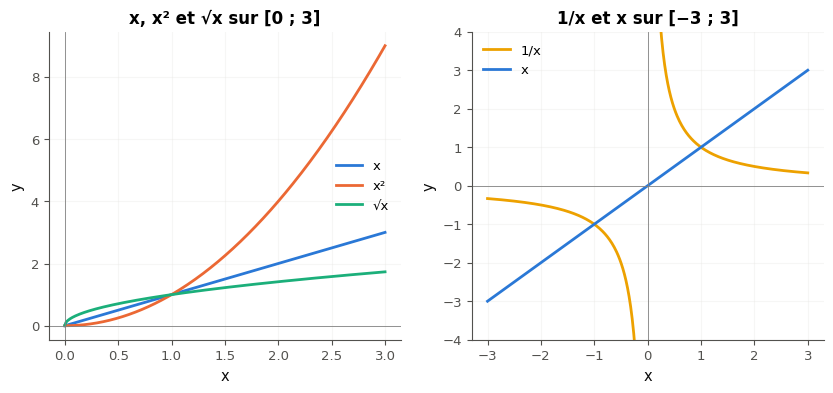

In [17]:
def plot_reference(axes):
    """axes[0]: x, x² and √x on [0, 3]. axes[1]: 1/x (in two pieces) and x on [−3, 3]. Legends, titles, axis labels."""
    xs = np.linspace(0, 3, 300)
    axes[0].plot(xs, xs, label="x")
    axes[0].plot(xs, xs**2, label="x²")
    axes[0].plot(xs, np.sqrt(xs), label="√x")
    axes[0].set_title("x, x² et √x sur [0 ; 3]")
    left, right = np.linspace(-3, -0.1, 200), np.linspace(0.1, 3, 200)
    axes[1].plot(left, 1 / left, color="C3", label="1/x")
    axes[1].plot(right, 1 / right, color="C3")
    xs2 = np.linspace(-3, 3, 200)
    axes[1].plot(xs2, xs2, color="C0", label="x")
    axes[1].set_ylim(-4, 4)
    axes[1].set_title("1/x et x sur [−3 ; 3]")
    for ax in axes:
        ax.axhline(0, color="gray", linewidth=0.6)
        ax.axvline(0, color="gray", linewidth=0.6)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.grid(True, alpha=0.3)
        ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_reference(axes)
plt.show()
answer_R3_21a, answer_R3_21b, answer_R3_21c = "]0 ; 1[", "]-oo ; 0[ U ]1 ; +oo[", [-1, 1]

In [18]:
wbm.record("R3.21a", "]0 ; 1[", kind="interval",
           mistakes={"pour x > 1, la droite y = x passe au-dessus de la racine carrée": "]1 ; +oo[",
                     "en 1, √x et x sont égaux : la borne est exclue": "]0 ; 1]"})
wbm.record("R3.21b", "]-oo ; 0[ U ]1 ; +oo[", kind="interval",
           mistakes={"x² > x vaut aussi pour les négatifs : x² est positif, x est négatif": "]1 ; +oo[",
                     "x² − x = x(x − 1) : positif à l'extérieur des racines, pas entre elles": "]0 ; 1["})
wbm.record("R3.21c", [-1, 1], ordered=False,
           mistakes={"1/x = x revient à x² = 1 : deux solutions, opposées": [1]})

WBM_ANSWER {"hash": "50e37fc707faf93e14f22054cf4ea8d8a7c75e51195af4e057eacd43cb45512f", "id": "R3.21a", "kind": "interval", "mistakes": {"18fe0933f39876a5ad38ed91470b1b7434f4fd0e42e22a424e85b165d0800ce5": "pour x > 1, la droite y = x passe au-dessus de la racine carrée", "d9d138c4b3f0b45a0da8f5a03af9ffdf775e92c30ea5fa341072caf5d5194bcf": "en 1, √x et x sont égaux : la borne est exclue"}}
📝 Ex R3.21a : réponse enregistrée (interval).
WBM_ANSWER {"hash": "f3169d1e488651641ecc7a514451ec07e3356a26b8cb72480ab7fd523351fd1a", "id": "R3.21b", "kind": "interval", "mistakes": {"5498689136adfb8ef633220a9c9c27febd01dc2a67c774deac9894a73fda4279": "x² − x = x(x − 1) : positif à l'extérieur des racines, pas entre elles", "bba58fdb778506bdb1cfc72ce0eecd2685825699f774640c976f4602ca04cdf1": "x² > x vaut aussi pour les négatifs : x² est positif, x est négatif"}}
📝 Ex R3.21b : réponse enregistrée (interval).
WBM_ANSWER {"hash": "a2f67ad28b2f16bbbefa618a4a3fab8a4a139a1f6f47b40016f826a02f0d7cc2", "id": "R3.

**Vérifications automatiques** (la figure elle-même se juge à l'œil).

In [19]:
with checked("R3.21 vérifications"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    try:
        created = drawn(plot_reference, axes)
    finally:
        plt.close(fig)                                 # only the checks below are shown here
    problems = []
    if created:
        problems.append("un dessin dans les axes reçus (axes[0].plot, axes[1].plot), sans créer de figure")
    else:
        if len(axes[0].lines) < 3:
            problems.append("les trois courbes x, x² et √x dans axes[0]")
        if len(axes[1].lines) < 2:
            problems.append("les courbes de 1/x et de x dans axes[1]")
        if any(ax.get_legend() is None for ax in axes):
            problems.append("une légende dans chaque graphique (label=, puis ax.legend())")
        for line in axes[1].lines:                     # 1/x drawn in one piece: a vertical line that does not exist
            xs = np.asarray(line.get_xdata(), dtype=float)
            ys = np.asarray(line.get_ydata(), dtype=float)
            ok = np.isfinite(xs) & np.isfinite(ys) & (xs != 0)
            if ok.sum() > 2 and np.allclose(xs[ok] * ys[ok], 1) and xs[ok].min() < 0 < xs[ok].max():
                problems.append("1/x en deux morceaux, un de chaque côté de 0, et non d'un seul trait")
                break
    if problems:
        print("❌ Ex R3.21 : il manque " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R3.21 : deux graphiques avec leurs courbes et leurs légendes, et 1/x en deux morceaux.")

✅ Ex R3.21 : deux graphiques avec leurs courbes et leurs légendes, et 1/x en deux morceaux.


💡 Pour b), $x^2 > x \iff x^2 - x > 0 \iff x(x - 1) > 0$ : un produit de deux facteurs, positif quand ils ont le même signe, donc pour $x < 0$ ou $x > 1$. La figure de gauche ne montre que $[0 \;;\; 3]$ : elle ne pouvait pas révéler les négatifs. Une lecture graphique suggère ; le calcul conclut.

### Ex R3.26 — Un graphique propre : titre, axes, légende 🛠️ ★ ⏱️ 15 min
**Objectif :** produire une figure qu'on peut montrer : titre, axes nommés avec leur unité, légende, point remarquable annoté.  
**Prérequis :** fiche §2, l'encadré « Un graphique propre » ; R0 (matplotlib) · **Parcours :** C

Une usine estime son coût de production par $C(q) = 0{,}5\,q^2 - 20\,q + 300$, en milliers d'euros, pour $q$ (en tonnes) entre 0 et 40. Son budget est de 150 milliers d'euros.

Complète `plot_cost(ax)`, qui dessine **dans l'axe `ax` qu'on lui donne** :
- la courbe de $C$ sur $[0 \;;\; 40]$ ;
- la droite horizontale du budget (`ax.axhline`) ;
- le point du minimum de $C$ (calcule-le d'abord à la main : §5), marqué d'un rond et annoté (`ax.annotate`) ;
- un titre, les axes nommés **avec leurs unités**, une légende, une grille.

La première cellule de vérification affiche ta figure ; la seconde regarde automatiquement qu'il ne manque rien d'essentiel. Compare ensuite ta figure à celle de `05_solutions.ipynb` : plusieurs mises en forme sont justes. Dans ta copie, lis sur ta figure les productions qui respectent le budget.

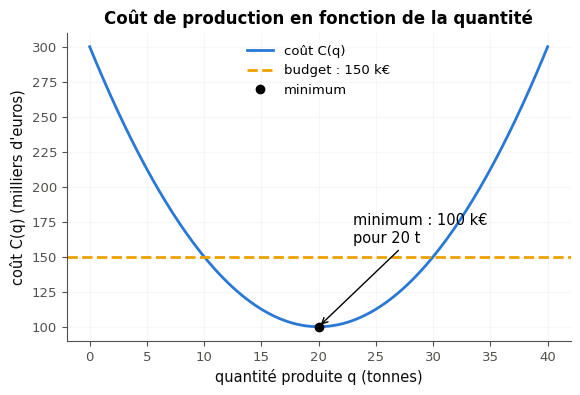

In [20]:
def plot_cost(ax):
    """Draw C(q) = 0.5 q² − 20 q + 300 on [0, 40], the budget line y = 150 and the marked minimum, in ax."""
    qs = np.linspace(0, 40, 200)
    ax.plot(qs, 0.5 * qs**2 - 20 * qs + 300, label="coût C(q)")
    ax.axhline(150, color="C3", linestyle="--", label="budget : 150 k€")
    ax.plot(20, 100, "o", color="black", label="minimum")
    ax.annotate("minimum : 100 k€\npour 20 t", (20, 100), xytext=(23, 160), arrowprops={"arrowstyle": "->"})
    ax.set_title("Coût de production en fonction de la quantité")
    ax.set_xlabel("quantité produite q (tonnes)")
    ax.set_ylabel("coût C(q) (milliers d'euros)")
    ax.grid(True, alpha=0.3)
    ax.legend()


fig, ax = plt.subplots(figsize=(6.5, 4))
plot_cost(ax)
plt.show()

**Vérifications automatiques** : ce qu'une figure à montrer doit contenir.

In [21]:
with checked("R3.26 vérifications"):
    fig, ax = plt.subplots(figsize=(6.5, 4))
    try:
        created = drawn(plot_cost, ax)
    finally:
        plt.close(fig)                                 # only the checks below are shown here
    problems = []
    if created:
        problems.append("un dessin dans l'axe ax reçu (ax.plot, ax.axhline…), sans créer de figure ni appeler plt.plot")
    elif not ax.get_title():
        problems.append("un titre (`ax.set_title`)")
    if not created and (not ax.get_xlabel() or not ax.get_ylabel()):
        problems.append("les deux axes nommés (`ax.set_xlabel`, `ax.set_ylabel`)")
    if not created and ax.get_legend() is None:
        problems.append("une légende (`label=` dans chaque `plot`, puis `ax.legend()`)")
    if not created and len(ax.lines) + len(ax.collections) < 3:          # ax.scatter or ax.hlines count too
        problems.append("la courbe, la droite du budget et le point du minimum (trois tracés au moins)")
    if problems:
        print("❌ Ex R3.26 : il manque " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R3.26 : titre, axes nommés, légende et trois tracés ; compare ta figure à celle de "
              "05_solutions.ipynb.")

✅ Ex R3.26 : titre, axes nommés, légende et trois tracés ; compare ta figure à celle de 05_solutions.ipynb.


💡 Le minimum est au sommet : $\alpha = -\frac{-20}{2 \times 0{,}5} = 20$ tonnes, et $C(20) = 200 - 400 + 300 = 100$ milliers d'euros. Le budget est respecté quand la courbe est sous la droite : $C(q) \le 150 \iff q^2 - 40q + 300 \le 0$, entre les racines 10 et 30, soit de 10 à 30 tonnes.

## Partie B · Fonctions affines et second degré

Fiche §3 et §5. Tes premières fonctions de `mymath/functions.py`, une famille de paraboles à déformer, et une grille de discriminants.

### Ex R3.18 — La fonction affine qui passe par deux points · `affine_from_points` 🔨 ★ ⏱️ 25 min
**Objectif :** programmer le calcul de la pente et de l'ordonnée à l'origine, et refuser une droite verticale.  
**Prérequis :** fiche §3 ; workbookIA 0A §100.6.2 (`raise`) · **mymath :** `functions.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en R2). Ouvre ta copie `mon_travail/mymath/functions.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Les tests comparent tes résultats à NumPy et à SymPy : écris le calcul toi-même, sans les appeler.

Écris `affine_from_points(p, q)` : `p` et `q` sont deux points `(x, y)`. Dépaquette-les (`(x1, y1), (x2, y2) = p, q`), lève une `ValueError` si leurs abscisses sont égales (une droite verticale n'est pas la courbe d'une fonction), puis calcule la pente et l'ordonnée à l'origine (fiche §3) ; rends le tuple `(m, c)`, deux flottants.

La vérification calcule `affine_from_points((-1, 4), (3, -4))`, puis le nom de l'erreur levée pour deux points de même abscisse (avec `raised`, de la cellule des outils).

In [22]:
mymath = wbm.load_mymath("ref")
print("affine_from_points((-1, 4), (3, -4)) =", mymath.functions.affine_from_points((-1, 4), (3, -4)))
print("même abscisse :", raised(mymath.functions.affine_from_points, (2, 1), (2, 5)))

affine_from_points((-1, 4), (3, -4)) = (-2.0, 2.0)
même abscisse : ValueError


In [23]:
wbm.record("R3.18a", [-2.0, 2.0], decimals=4,
           mistakes={"la pente est (y₂ − y₁)/(x₂ − x₁) : même ordre en haut et en bas": [2.0, 6.0],
                     "c = y₁ − m·x₁ : attention au signe de x₁": [-2.0, 6.0],
                     "rends le couple dans l'ordre (m, c)": [2.0, -2.0]})
wbm.record("R3.18b", "ValueError",
           mistakes={"teste x1 == x2 avant de diviser, et lève une ValueError": "ZeroDivisionError",
                     "deux points de même abscisse : la fonction doit lever une ValueError (raise), pas rendre un "
                     "résultat": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : "
                     "raise ValueError(\"...\")": {"Exception", "TypeError", "AssertionError"}})

WBM_ANSWER {"decimals": 4, "element_coarse": [["46b302035b69df8651f1aaefbeafffb638afec5132709d0d62423c1e487ac073"], ["60d70f5da29ef6d893a21031a9a4affcafe63cefb065068c111658e109651987"]], "element_hashes": ["97a28dfc93a7a89146dfa497245ee18efd47c9292b47b5a6fbd2562138cf3e1c", "7904a082c31b91b02193ee7d63afa1cb1ae7abea06b4679cac8e332febd6c10f"], "hash": "3c4820c446969d485c2d6b7b5c6e94b2c1a4216465fdf781e456b1fca225e6c3", "id": "R3.18a", "kind": "array", "mistakes": {"0bbbee47d0613b630a3982ab3864c4783d4ea9cb57cc15f089725e7c9333c98c": "c = y₁ − m·x₁ : attention au signe de x₁", "10ea10e50dbaea7e57531d0f8c0e8693e4a66d346cd247aceeeb37b0cc980cd7": "rends le couple dans l'ordre (m, c)", "d134a518564b768c7b91fcec5ed9fb123f2a601833618b4160881937aaccb2ab": "la pente est (y₂ − y₁)/(x₂ − x₁) : même ordre en haut et en bas"}, "shape": [2]}
📝 Ex R3.18a : réponse enregistrée (array, 4 décimale(s)).
WBM_ANSWER {"hash": "d2ab14998f27372eb79b1cd130237e93d0d4098d75c76f04d791316467d5891a", "id": "R3.18b", "kin

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_r3_functions.py", "test_affine_from_points_", impl="ref")

pytest: 8 passed, 30 deselected in 0.21s


### Ex R3.19 — Racines et sommet d'un polynôme du second degré · `quadratic_roots`, `quadratic_vertex` 🔨 ★★ ⏱️ 40 min
**Objectif :** programmer les trois cas du discriminant et la forme canonique.  
**Prérequis :** fiche §5 ; R3.18 · **mymath :** `functions.py` · **Parcours :** C, E

Dans `mon_travail/mymath/functions.py` :
- a) `quadratic_roots(a, b, c)` : une `ValueError` si `a == 0` ; sinon le discriminant décide (fiche §5) : deux racines (`math.sqrt`, rendues dans l'ordre croissant, même quand `a` est négatif), une racine double, ou la liste vide. Compare le discriminant à 0 avec `==` : les tests de la racine double utilisent des entiers. Le squelette n'importe pas `math` : ajoute `import math` en haut du fichier.
- b) `quadratic_vertex(a, b, c)` : une `ValueError` si `a == 0` ; sinon le tuple `(alpha, beta)` de la forme canonique.

La vérification calcule `quadratic_roots(-2, 7, -3)`, regarde si `quadratic_roots(1, 2, 3)` vaut bien `[]`, puis calcule `quadratic_vertex(-1, 6, -5)`.

In [25]:
mymath = wbm.load_mymath("ref")
print("quadratic_roots(-2, 7, -3)  =", mymath.functions.quadratic_roots(-2, 7, -3))
print("quadratic_roots(1, 2, 3)    =", mymath.functions.quadratic_roots(1, 2, 3))
print("quadratic_vertex(-1, 6, -5) =", mymath.functions.quadratic_vertex(-1, 6, -5))

quadratic_roots(-2, 7, -3)  = [0.5, 3.0]
quadratic_roots(1, 2, 3)    = []
quadratic_vertex(-1, 6, -5) = (3.0, 4.0)


In [26]:
wbm.record("R3.19a", [0.5, 3.0], decimals=4,
           mistakes={"le dénominateur est 2a, pas 2": [-6.0, -1.0],
                     "rends les racines dans l'ordre croissant : avec a négatif, (−b − √Δ)/(2a) est la plus grande":
                         [3.0, 0.5],
                     "priorités : -b + math.sqrt(d) / 2 * a ne divise que la racine, puis multiplie par a ; "
                     "écris (-b + math.sqrt(d)) / (2 * a)": [-12.0, -2.0],
                     "priorités : -b + math.sqrt(d) / 2 * a ne divise que la racine ; écris (-b + math.sqrt(d)) / "
                     "(2 * a), et rends les racines dans l'ordre croissant": [-2.0, -12.0],
                     "priorités : / 2 * a divise par 2 puis multiplie par a ; écris / (2 * a)": [2.0, 12.0],
                     "priorités : / 2 * a divise par 2 puis multiplie par a ; écris / (2 * a), et rends les racines "
                     "dans l'ordre croissant": [12.0, 2.0]})
wbm.record("R3.19b", True,
           mistakes={"un discriminant négatif : pas de racine réelle, la fonction doit rendre la liste vide": False})
wbm.record("R3.19c", [3.0, 4.0], decimals=4,
           mistakes={"α = −b/(2a) : avec a négatif, attention au signe": [-3.0, -32.0],
                     "β = c − b²/(4a) : attention au signe": [3.0, -14.0]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["a08bd0d8868ea9f7a4f27cf99a945bfedcda0f7e781fb8423611553f5e7788d7"], ["a8d0ae473ef3b915c77b93478f1215f8666411ac7b201ed7d2195e98f095cf3f"]], "element_hashes": ["207749bd217be162f63c9e9cade2d2f249eab339de88deab1aef3948a8419ffb", "35ffa0c32ff12138c3e05bfeba1f9d3f4af5fe749ec6c98e0a238d46f64f7ae4"], "hash": "1ce1e09ffc9c7be5490ae3128bae28828cabdc54cf4fea811abaf73446cf2b10", "id": "R3.19a", "kind": "array", "mistakes": {"20388fb9767b8de43804bb0d321ecb81cff1075faf6abad6c2fd2fec6cd7f8ac": "priorités : / 2 * a divise par 2 puis multiplie par a ; écris / (2 * a)", "3d8dd9cbee87339bbb8e5af58b826ac69004d6910428651a1c43959b17c48716": "priorités : -b + math.sqrt(d) / 2 * a ne divise que la racine ; écris (-b + math.sqrt(d)) / (2 * a), et rends les racines dans l'ordre croissant", "4ddcfa558a6b89054b435f93e0be6428ddef5258f4dca82099386ba65cb3270f": "priorités : -b + math.sqrt(d) / 2 * a ne divise que la racine, puis multiplie par a ; écris (-b + math.sqrt

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [27]:
run_pytest_group("tests/test_r3_functions.py", "test_quadratic_roots_ or test_quadratic_vertex_", impl="ref")

pytest: 15 passed, 23 deselected in 0.77s


💡 Le tri compte quand `a` est négatif : $\frac{-b - \sqrt{\Delta}}{2a}$ est alors la **plus grande** racine (on divise par un négatif). `sorted([...])` règle la question sans réfléchir au signe.

### Ex R3.22 — Faire varier a, b et c : déformer une parabole 🎨 ★★ ⏱️ 20 min
**Objectif :** voir ce que chaque paramètre fait à une parabole, et pourquoi la forme canonique le dit d'un coup d'œil.  
**Prérequis :** fiche §5 · **Parcours :** C, E

Complète `plot_families(axes)`, qui reçoit trois axes côte à côte et trace, sur $[-4 \;;\; 4]$ :
1. dans `axes[0]`, la famille $y = a\,x^2$ pour $a \in \{-2, -0{,}5, 0{,}5, 1, 2\}$ ;
2. dans `axes[1]`, la famille $y = x^2 + c$ pour $c \in \{-3, 0, 2\}$ ;
3. dans `axes[2]`, la famille $y = (x - h)^2$ pour $h \in \{-2, 0, 3\}$.

Une légende dans chaque graphique (la valeur du paramètre), un titre, la même fenêtre verticale $[-6 \;;\; 8]$ partout pour comparer.

Puis réponds dans ta copie : que fait $a$ (son signe, sa taille) ? que fait $c$ ? que fait $h$ ? En déduire, sans calcul, à quoi ressemble la courbe de $y = 2(x - 3)^2 - 1$ par rapport à celle de $y = x^2$. Et le coefficient $b$ de $ax^2 + bx + c$ : pourquoi est-il plus difficile à « lire » que $a$, $\alpha$ et $\beta$ ?

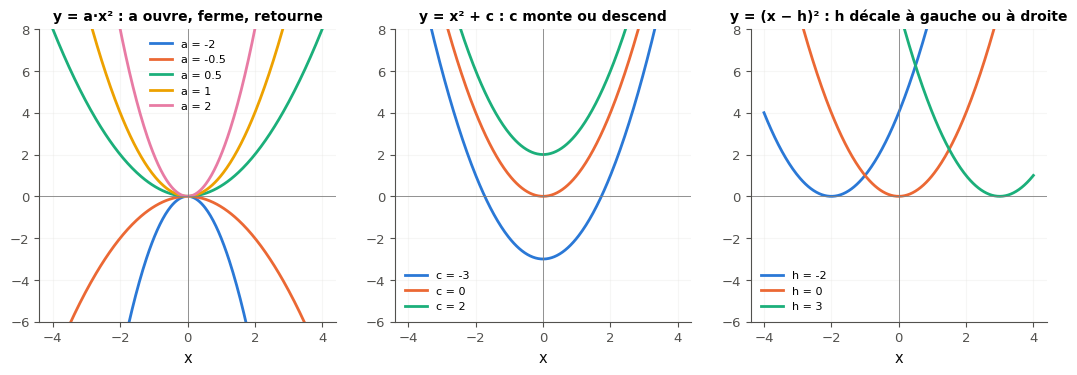

In [28]:
def plot_families(axes):
    """Three families of parabolas: y = a x², y = x² + c, y = (x − h)², one per axis, with legends and titles."""
    xs = np.linspace(-4, 4, 300)
    for a in (-2, -0.5, 0.5, 1, 2):
        axes[0].plot(xs, a * xs**2, label=f"a = {a}")
    for c in (-3, 0, 2):
        axes[1].plot(xs, xs**2 + c, label=f"c = {c}")
    for h in (-2, 0, 3):
        axes[2].plot(xs, (xs - h) ** 2, label=f"h = {h}")
    titles = ["y = a·x² : a ouvre, ferme, retourne", "y = x² + c : c monte ou descend",
              "y = (x − h)² : h décale à gauche ou à droite"]
    for ax, title in zip(axes, titles):
        ax.set_ylim(-6, 8)
        ax.axhline(0, color="gray", linewidth=0.6)
        ax.axvline(0, color="gray", linewidth=0.6)
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("x")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)


fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
plot_families(axes)
plt.show()

**Vérifications automatiques** (la figure elle-même se juge à l'œil).

In [29]:
with checked("R3.22 vérifications"):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    try:
        created = drawn(plot_families, axes)
    finally:
        plt.close(fig)
    problems = []
    if created:
        problems.append("un dessin dans les axes reçus (axes[0].plot…), sans créer de figure")
    elif any(len(ax.lines) < 3 for ax in axes):
        problems.append("au moins trois paraboles dans chacun des trois graphiques")
    if not created and not all(ax.get_title() for ax in axes):
        problems.append("un titre par graphique, qui dit quel paramètre varie")
    if problems:
        print("❌ Ex R3.22 : il manque " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R3.22 : trois familles de paraboles, chacune avec son titre ; à toi de conclure dans ta copie.")

✅ Ex R3.22 : trois familles de paraboles, chacune avec son titre ; à toi de conclure dans ta copie.


💡 $a$ règle l'ouverture (plus $|a|$ est grand, plus la parabole est fermée) et le sens ($a < 0$ la retourne) ; $c$ la translate verticalement ; $h$ la translate horizontalement, vers la droite quand $h > 0$ (le signe moins de $(x - h)$ trompe souvent). Donc $2(x - 3)^2 - 1$ est la parabole $y = x^2$ resserrée d'un facteur 2, puis décalée de 3 vers la droite et de 1 vers le bas : sommet $(3 \;;\; -1)$. Le coefficient $b$, lui, déplace le sommet en biais : il change à la fois $\alpha$ et $\beta$.

### Ex R3.24 — Combien de racines ? Le signe du discriminant sur une grille de paramètres 🔬 ★★ ⏱️ 20 min
**Objectif :** voir sur une grille de paramètres quand un second degré a deux, une ou aucune racine, et trouver la frontière.  
**Prérequis :** fiche §5 ; R3.19 · **Parcours :** C

On étudie tous les polynômes $x^2 + bx + c$ avec $b$ et $c$ **entiers** de $-5$ à $5$ : 121 polynômes.

- a) Écris `count_roots()` : la liste `[n2, n1, n0]`, où `n2` est le nombre de ces polynômes qui ont deux racines, `n1` le nombre qui en ont une, et `n0` le nombre qui n'en ont aucune. Deux boucles `for` imbriquées et le discriminant suffisent (ou ta fonction `quadratic_roots` de R3.19).
- b) Sur la figure de l'expérience, les points « une racine » sont sur une courbe qui sépare les deux autres familles. Écris `boundary(b)`, qui donne le $c$ de cette frontière en fonction de $b$ (il s'agit de résoudre $\Delta = 0$ en $c$), puis donne son expression en `b`, entre guillemets.

L'expérience colore les 121 points selon le signe de $\Delta$ et trace ta frontière par-dessus.

In [30]:
def count_roots():
    """[n2, n1, n0]: how many x² + bx + c (b, c integers from −5 to 5) have two, one or no real root."""
    counts = [0, 0, 0]
    for b in range(-5, 6):
        for c in range(-5, 6):
            delta = b * b - 4 * c
            counts[0 if delta > 0 else 1 if delta == 0 else 2] += 1
    return counts


def boundary(b):
    """The c for which x² + bx + c has exactly one root (works on a NumPy array of b)."""
    return b**2 / 4


print("deux, une, aucune racine :", count_roots())
answer_R3_24b = "b**2/4"

deux, une, aucune racine : [85, 5, 31]


In [31]:
wbm.record("R3.24a", [85, 5, 31],
           mistakes={"l'ordre demandé est [deux racines, une racine, aucune racine]": [31, 5, 85],
                     "b et c vont de −5 à 5 inclus : range(-5, 6) dans les deux boucles": [73, 5, 22],
                     "b va de −5 à 5 inclus : range(-5, 6) aussi pour b": [74, 5, 31],
                     "c va de −5 à 5 inclus : range(-5, 6) aussi pour c": [83, 5, 22]})
wbm.record("R3.24b", "b**2/4", kind="expr", variables=("b",),
           mistakes={"Δ = b² − 4c = 0 : isole c, en divisant par 4": "b**2",
                     "Δ = b² − 4ac avec a = 1 : il y a un facteur 4": "b**2/2"})

WBM_ANSWER {"decimals": 0, "element_hashes": ["6ace7e3d6216774d54e789e1925ecd216543837518b4667dac1b0e901a9f3bd4", "1d2c03c2134b8dd29dc8c6f7799b25b9106069c5bb893345d6804d84c27b8aeb", "92f30d83d813e38f209f7ee2c97c1998d42defc9f56d054d5ec42e58e770a2eb"], "hash": "ebbac02a883b59794891328c3991a53a024b704a45f85ceeda2697baac1bc6a8", "id": "R3.24a", "integer": true, "kind": "array", "mistakes": {"3960c83516aa96e5d50e4f23ea583397bff093965f5ebf0004788e0bb65f5f7c": "b et c vont de −5 à 5 inclus : range(-5, 6) dans les deux boucles", "4ac0761d7c839b1b7e1137418cf5c20ae4a6ee6598b1f982f7f88c64fe7021c8": "c va de −5 à 5 inclus : range(-5, 6) aussi pour c", "a261980be6716811d12cb4226ab095f5a16429fa4bfc2f17ec5b2991a091607e": "l'ordre demandé est [deux racines, une racine, aucune racine]", "bdad2c7e8b9b0c368f544c1571ede2465b33524797c66123c2915ddd841730bc": "b va de −5 à 5 inclus : range(-5, 6) aussi pour b"}, "shape": [3]}
📝 Ex R3.24a : réponse enregistrée (array, 0 décimale(s)).
WBM_ANSWER {"hash": "8833

**L'expérience** : les 121 polynômes, colorés selon le signe du discriminant, et ta frontière.

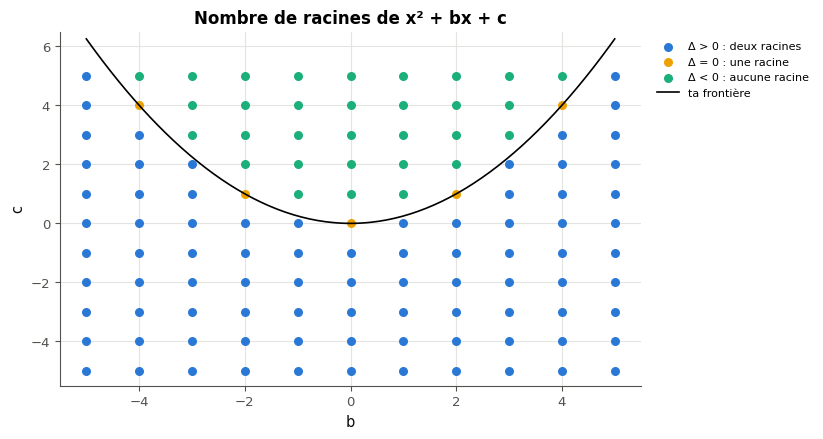

In [32]:
with checked("R3.24 figure"):
    bs, cs = np.meshgrid(range(-5, 6), range(-5, 6))
    deltas = bs**2 - 4 * cs
    grid = np.linspace(-5, 5, 200)
    frontier = boundary(grid)                     # before the figure: no half-drawn figure if boundary is not written
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    for mask, colour, label in [(deltas > 0, "C0", "Δ > 0 : deux racines"), (deltas == 0, "C3", "Δ = 0 : une racine"),
                                (deltas < 0, "C2", "Δ < 0 : aucune racine")]:
        ax.scatter(bs[mask], cs[mask], color=colour, label=label, s=30)
    ax.plot(grid, frontier, color="black", linewidth=1.2, label="ta frontière")
    ax.set_xlim(-5.5, 5.5)
    ax.set_ylim(-5.5, 6.5)
    ax.set_xlabel("b")
    ax.set_ylabel("c")
    ax.set_title("Nombre de racines de x² + bx + c")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.show()

💡 Les polynômes à une racine sont ceux où $c = \frac{b^2}{4}$ est entier : $b$ pair, soit 5 points. Au-dessous de la parabole $c = \frac{b^2}{4}$ (pour $c$ petit), $\Delta > 0$ : deux racines ; au-dessus, aucune. Tirer $b$ et $c$ au hasard donne bien plus souvent deux racines : 85 fois sur 121 ici.

## Partie C · Composition, réciproque et polynômes

Fiche §7 à §9. Composer en Python, prédire deux composées, une chasse à l'erreur, et le schéma de Horner.

### Ex R3.20 — Composer deux fonctions · `compose` 🔨 ★ ⏱️ 25 min
**Objectif :** programmer une fonction qui fabrique une fonction (une fermeture), dans le bon ordre.  
**Prérequis :** fiche §7 ; workbookIA 0A §100.5.3 (fonctions comme valeurs) et §100.5.4 (fermetures) · **mymath :** `functions.py` · **Parcours :** C, E

Écris `compose(f, g)` dans `mon_travail/mymath/functions.py` : elle **renvoie une nouvelle fonction**, qui à `x` associe `f(g(x))`. Définis cette fonction à l'intérieur de `compose` (une fermeture, comme `then_add` dans la fiche §7), puis renvoie-la **sans l'appeler**.

La vérification fabrique $x \mapsto (x - 1)^2$ et $x \mapsto x^2 - 1$ avec `compose`, et les calcule en 4.

In [33]:
mymath = wbm.load_mymath("ref")
square_after = mymath.functions.compose(lambda t: t**2, lambda t: t - 1)
minus_after = mymath.functions.compose(lambda t: t - 1, lambda t: t**2)
print("(x − 1)² en 4 :", square_after(4), " ;  x² − 1 en 4 :", minus_after(4))

(x − 1)² en 4 : 9  ;  x² − 1 en 4 : 15


In [34]:
wbm.record("R3.20", [9, 15],
           mistakes={"compose(f, g) applique g d'abord, puis f": [15, 9]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["9a9f1b96bf5d54b4d26e784b349742a70c407f90d7a2ebfed6f5c400da5e84eb", "603cc493c71d10ef1b994461827c518e74c5eb33ba04037ef76a372392944687"], "hash": "c35570babd84dbb8f48c037a8585a0828e37818e4aff4da03c4b21820cb125b8", "id": "R3.20", "integer": true, "kind": "array", "mistakes": {"d23126c1ce165ffb2818d9544cb4233784c1b1e0f8b535273c85402eeb589dd1": "compose(f, g) applique g d'abord, puis f"}, "shape": [2]}
📝 Ex R3.20 : réponse enregistrée (array, 0 décimale(s)).


**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [35]:
run_pytest_group("tests/test_r3_functions.py", "test_compose_", impl="ref")

pytest: 6 passed, 32 deselected in 0.19s


💡 `return composite` (sans parenthèses) renvoie la fonction elle-même ; `return composite(x)` n'aurait pas de sens ici, puisque `compose` ne reçoit pas de `x`. C'est exactement ce que fait une couche suivie d'une activation dans un réseau : une composée, construite une fois, appelée sur chaque donnée.

### Ex R3.23 — Prédire f∘g et g∘f pour « valeur absolue » et « moins 3 » 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir le résultat d'une composée dans les deux ordres, puis le voir sur les courbes.  
**Prérequis :** fiche §7 · **Parcours :** C

On pose $f(x) = |x|$ (« valeur absolue ») et $g(x) = x - 3$ (« moins 3 »). **Avant d'exécuter quoi que ce soit**, prédis :
- a) $(f \circ g)(1)$ ;
- b) $(g \circ f)(1)$ ;
- c) $(f \circ g)(-2)$ ;
- d) $(g \circ f)(-2)$.

Écris tes quatre prédictions, vérifie-les, puis lance l'expérience : elle calcule les quatre valeurs et trace les deux composées. Dans ta copie : pour quels $x$ les deux composées sont-elles égales ? Pourquoi ?

In [36]:
wbm.record("R3.23a", abs(1 - 3), prediction=True,
           mistakes={"f∘g applique g d'abord (moins 3), puis la valeur absolue": -2})
wbm.record("R3.23b", abs(1) - 3, prediction=True,
           mistakes={"g∘f applique f d'abord (la valeur absolue), puis moins 3": 2})
wbm.record("R3.23c", abs(-2 - 3), prediction=True,
           mistakes={"f∘g : on retire 3 d'abord, puis on prend la valeur absolue du résultat": -1,
                     "−2 − 3 se calcule avec les signes avant de prendre la valeur absolue": 1})
wbm.record("R3.23d", abs(-2) - 3, prediction=True,
           mistakes={"g∘f : la valeur absolue d'abord, puis on retire 3": 5})

WBM_ANSWER {"hash": "7cf68a80c21babb983ccfd0b2536abd0f29e098996e8cb7817b8b3876386d4dd", "id": "R3.23a", "kind": "int", "magnitude": 0, "mistakes": {"c204e3f2cbcbac8a4f933c476ded135dd8c207741211ee0a6bcdf48bea8d89f2": "f∘g applique g d'abord (moins 3), puis la valeur absolue"}, "prediction": true, "sign": 1}
📝 Ex R3.23a : réponse enregistrée (int).
WBM_ANSWER {"hash": "2918ea447e18fffd096b313218d701b4d5ad4ba06359a901e57293fc605bc8e7", "id": "R3.23b", "kind": "int", "magnitude": 0, "mistakes": {"2a4252331fd1268115840e42f4bdb18cd77e7b8743a98d5b3594213ff827649c": "g∘f applique f d'abord (la valeur absolue), puis moins 3"}, "prediction": true, "sign": -1}
📝 Ex R3.23b : réponse enregistrée (int).
WBM_ANSWER {"hash": "8977b3482c95504cd22dc731d5a7aed7d81600c3e0fe3d8e53fbc859e8b31be0", "id": "R3.23c", "kind": "int", "magnitude": 0, "mistakes": {"1faa8e27a4b075714c57fe1583b9b15107b7fa40bbdf9563ba6659070a3b7c17": "−2 − 3 se calcule avec les signes avant de prendre la valeur absolue", "d07e48840c19

**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

(f∘g)(1) = 2  ; (g∘f)(1) = -2
(f∘g)(−2) = 5  ; (g∘f)(−2) = -1


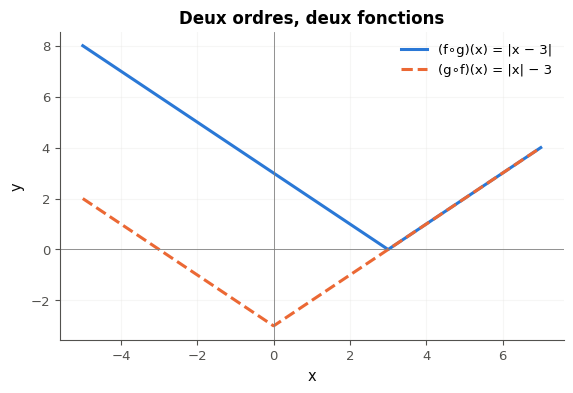

In [37]:
f = abs
g = lambda t: t - 3
print("(f∘g)(1) =", f(g(1)), " ; (g∘f)(1) =", g(f(1)))
print("(f∘g)(−2) =", f(g(-2)), " ; (g∘f)(−2) =", g(f(-2)))
xs = np.linspace(-5, 7, 400)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(xs, np.abs(xs - 3), label="(f∘g)(x) = |x − 3|", linewidth=2.2)
ax.plot(xs, np.abs(xs) - 3, "--", label="(g∘f)(x) = |x| − 3", linewidth=2.2)
ax.axhline(0, color="gray", linewidth=0.6)
ax.axvline(0, color="gray", linewidth=0.6)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Deux ordres, deux fonctions")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

💡 Les deux courbes coïncident pour $x \ge 3$ : alors $x - 3 \ge 0$ et $x \ge 0$, donc $|x - 3| = x - 3$ et $|x| - 3 = x - 3$. Pour $x < 3$, $|x - 3|$ est positif (une distance) alors que $|x| - 3$ peut être négatif. Même deux fonctions très simples ne commutent pas.

### Ex R3.25 — Chasse à l'erreur : composition, réciproque et racines 🐛 ★★ ⏱️ 20 min
**Objectif :** repérer les erreurs classiques sur les composées, les réciproques et le second degré, et les corriger.  
**Prérequis :** fiche §5, §7 et §8, « Les pièges classiques » · **Parcours :** C, E

Un camarade a fait sept calculs. **Sans rien exécuter d'abord**, trouve ceux qui sont faux. On pose $f(x) = 5x - 1$ et $g(x) = x^2$.

| | Calcul |
|---|---|
| A | $(f \circ g)(x) = (5x - 1)^2$ |
| B | $f^{-1}(x) = \dfrac{1}{5x - 1}$ |
| C | les racines de $x^2 - 2x - 15$ sont $-5$ et $3$ |
| D | $3x^2 + 6x + 1 = 3(x + 1)^2 - 2$ |
| E | $x \mapsto 3 - x$ est décroissante sur $\mathbb{R}$ |
| F | le discriminant de $2x^2 - 3x - 4$ vaut $9 - 32 = -23$ |
| G | pour $4x^2 - 4x - 3$, $\Delta = 64$, donc les racines sont $4 \pm \frac{8}{8}$, soit 3 et 5 |

- a) Les lettres des calculs faux, dans un texte.
- b) Le bon $(f \circ g)(x)$ : une liste de coefficients.
- c) Les bonnes racines de $x^2 - 2x - 15$ : une liste.
- d) Le bon discriminant de $2x^2 - 3x - 4$.
- e) Les bonnes racines de $4x^2 - 4x - 3$ : une liste.

In [38]:
import sympy as sp

x = sp.Symbol("x")
f = lambda t: 5 * t - 1
g = lambda t: t**2
print("A : f(g(x)) =", sp.expand(f(g(x))), " ; (5x − 1)² =", sp.expand((5 * x - 1) ** 2))
print("B : f⁻¹(f(2)) doit redonner 2 ; avec la formule proposée, on obtient", 1 / (5 * f(2) - 1), "-> faux")
print("C :", sp.solve(x**2 - 2 * x - 15, x))
print("D :", sp.expand(3 * (x + 1) ** 2 - 2))
print("F :", (-3) ** 2 - 4 * 2 * (-4))
print("G :", sp.solve(4 * x**2 - 4 * x - 3, x))

A : f(g(x)) = 5*x**2 - 1  ; (5x − 1)² = 25*x**2 - 10*x + 1
B : f⁻¹(f(2)) doit redonner 2 ; avec la formule proposée, on obtient 0.022727272727272728 -> faux
C : [-3, 5]
D : 3*x**2 + 6*x + 1
F : 41
G : [-1/2, 3/2]


In [39]:
wbm.record("R3.25a", "ABCFG",
           mistakes={"il manque une ligne fautive : une composée calculée dans le mauvais ordre": "BCFG",
                     "il manque une ligne fautive : une réciproque confondue avec l'inverse": "ACFG",
                     "il manque une ligne fautive : des racines qui ont pris le mauvais signe": "ABFG",
                     "il manque une ligne fautive : un discriminant qui a perdu un signe": "ABCG",
                     "il manque une ligne fautive : une formule des racines qui ne divise pas tout le numérateur": "ABCF",
                     "une ligne de trop : la ligne (D) est correcte ; relis ce qu'elle fait": "ABCDFG",
                     "une ligne de trop : la ligne (E) est correcte ; relis ce qu'elle fait": "ABCEFG",
                     "la ligne (D) est correcte, et il manque une ligne fautive : une composée calculée dans le mauvais ordre": "BCDFG",
                     "la ligne (E) est correcte, et il manque une ligne fautive : une composée calculée dans le mauvais ordre": "BCEFG",
                     "la ligne (D) est correcte, et il manque une ligne fautive : une réciproque confondue avec l'inverse": "ACDFG",
                     "la ligne (E) est correcte, et il manque une ligne fautive : une réciproque confondue avec l'inverse": "ACEFG",
                     "la ligne (D) est correcte, et il manque une ligne fautive : des racines qui ont pris le mauvais signe": "ABDFG",
                     "la ligne (E) est correcte, et il manque une ligne fautive : des racines qui ont pris le mauvais signe": "ABEFG",
                     "la ligne (D) est correcte, et il manque une ligne fautive : un discriminant qui a perdu un signe": "ABCDG",
                     "la ligne (E) est correcte, et il manque une ligne fautive : un discriminant qui a perdu un signe": "ABCEG",
                     "la ligne (D) est correcte, et il manque une ligne fautive : une formule des racines qui ne divise pas tout le numérateur": "ABCDF",
                     "la ligne (E) est correcte, et il manque une ligne fautive : une formule des racines qui ne divise pas tout le numérateur": "ABCEF",
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "B", "C", "F", "G", "AB", "AC", "AF", "AG", "BC", "BF", "BG", "CF", "CG", "FG", "ABC", "ABF", "ABG", "ACF", "ACG", "AFG", "BCF", "BCG", "BFG", "CFG"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"D", "E", "AD", "AE", "BD", "BE", "CD", "CE", "DE", "DF", "DG", "EF", "EG", "ABD", "ABE", "ACD", "ACE", "ADE", "ADF", "ADG", "AEF", "AEG", "BCD", "BCE", "BDE", "BDF", "BDG", "BEF", "BEG", "CDE", "CDF", "CDG", "CEF", "CEG", "DEF", "DEG", "DFG", "EFG", "ABCD", "ABCE", "ABDE", "ABDF", "ABDG", "ABEF", "ABEG", "ACDE", "ACDF", "ACDG", "ACEF", "ACEG", "ADEF", "ADEG", "ADFG", "AEFG", "BCDE", "BCDF", "BCDG", "BCEF", "BCEG", "BDEF", "BDEG", "BDFG", "BEFG", "CDEF", "CDEG", "CDFG", "CEFG", "DEFG", "ABCDE", "ABDEF", "ABDEG", "ACDEF", "ACDEG", "ADEFG", "BCDEF", "BCDEG", "BDEFG", "CDEFG", "ABCDEF", "ABCDEG", "ABDEFG", "ACDEFG", "BCDEFG"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDEFG"}})
wbm.record("R3.25b", [5, 0, -1],
           mistakes={"f∘g applique g d'abord : on remplace x par x² dans f": [25, -10, 1]})
wbm.record("R3.25c", [-3, 5], ordered=False,
           mistakes={"les racines sont (−b ± √Δ)/(2a) : −b est positif ici": [-5, 3]})
wbm.record("R3.25d", 41,
           mistakes={"−4ac avec c négatif : moins par moins donne plus": -23})
wbm.record("R3.25e", [-0.5, 1.5], ordered=False, decimals=4,
           mistakes={"tout le numérateur −b ± √Δ est divisé par 2a, pas seulement √Δ": [3.0, 5.0]})

WBM_ANSWER {"hash": "6baabac1af3ac6835d72f05183ca0ebefe34e7d16d155788a8b901b57145a959", "id": "R3.25a", "kind": "str", "mistakes": {"0206a4407b0df9ec3e5e5c6bf42df43d48a81692c8cf2461ee3d6369534bc139": "il manque une ligne fautive : une composée calculée dans le mauvais ordre", "02aa2278df63d4c50229bd5e305f0349801f49d2efdff6f3953d6c9f967a61f8": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "02d8bd9effd96b30c2352756c60bdde36f9aa029451104a5fd5ee137cfa400d9": "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple", "0453e3b0a099738bbec3cd5b8f14a92ca2a7ee40719de373a5b2c2f493b26298": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "06916a7908e4c2f6ae0be59619237f8ae162e6adceb3ddb2b5d5c626ae7bd43f": "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple", "08c1a33e936c4e55bddb8a71c10061ba62b7cc

💡 Les deux calculs justes ont leur piège apparent : D se vérifie en redéveloppant, $3(x^2 + 2x + 1) - 2 = 3x^2 + 6x + 1$ ; E est une fonction affine de pente $-1$. Pour B, la réciproque de $f$ est $x \mapsto \frac{x + 1}{5}$ : elle défait « fois 5, moins 1 » en faisant « plus 1, divisé par 5 ».

### Ex R3.17 — Évaluer un polynôme par Horner · `polyval` 🔨 ★ ⏱️ 25 min
**Objectif :** programmer le schéma de Horner, qui évalue un polynôme sans calculer aucune puissance.  
**Prérequis :** fiche §9 ; workbookIA 0A §100.4.2 (boucle `for`) · **mymath :** `functions.py` · **Parcours :** C

> **Mode d'emploi `mymath`** (comme en R2). Ouvre ta copie `mon_travail/mymath/functions.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Les tests comparent tes résultats à NumPy et à SymPy : écris le calcul toi-même, sans les appeler.

Écris `polyval(coefficients, x)` : les coefficients vont du plus haut degré au terme constant (fiche §9). Pars de 0, puis, pour chaque coefficient, multiplie la valeur courante par `x` et ajoute le coefficient. Sans `**` : c'est tout l'intérêt du schéma. Avec des entiers, le résultat reste entier ; avec un tableau NumPy en `x`, les mêmes opérations marchent case par case.

La vérification calcule `polyval([1, -2, 0, 3], -2)` et `polyval([0.5, 1], 4)`.

In [40]:
mymath = wbm.load_mymath("ref")
print("polyval([1, -2, 0, 3], -2) =", mymath.functions.polyval([1, -2, 0, 3], -2))
print("polyval([0.5, 1], 4)       =", mymath.functions.polyval([0.5, 1], 4))

polyval([1, -2, 0, 3], -2) = -13
polyval([0.5, 1], 4)       = 3.0


In [41]:
wbm.record("R3.17a", -13,
           mistakes={"le premier coefficient va avec le plus haut degré : ne parcours pas la liste à l'envers": -19,
                     "la valeur courante part de 0, pas de 1": 3,
                     "à chaque étape, multiplie d'abord la valeur courante par x, puis ajoute le coefficient": 26})
wbm.record("R3.17b", 3.0, decimals=4,
           mistakes={"le premier coefficient va avec le plus haut degré": 4.5})

WBM_ANSWER {"hash": "234eae93b872e72bc286667a1a0ca29351f9419a5f41744e2f6f836efd823c44", "id": "R3.17a", "kind": "int", "magnitude": 1, "mistakes": {"00f81d33b73882d9331ad3eab669c2171e07e1e0b35b410ab300ba5601096df8": "la valeur courante part de 0, pas de 1", "a6bc8839547742567a7cb0756f993ecf1dd2b9550dd87c442602fd9eb21d7592": "le premier coefficient va avec le plus haut degré : ne parcours pas la liste à l'envers", "d2420692393bc5604e9bf925014c02ec68766b24e796b3adb37d34e08bd71f47": "à chaque étape, multiplie d'abord la valeur courante par x, puis ajoute le coefficient"}, "sign": -1}
📝 Ex R3.17a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 4, "hash": "0c82683cac268a2e11189bfcde5f3fe2ea5b02707538fc83aaf08357eb4b209f", "hash_coarse": "cc3ae806985660924845317f66cf01e7a81f6bd1e4251e125fb92b07e2466927", "id": "R3.17b", "kind": "float", "magnitude": 0, "mistakes": {"4cf2cfb9011590acecf8fc137bd5c51f80fff401dfc5077b5bddd9df1417bf7b": "le premier coefficient va avec le plus haut degré"}, "

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [42]:
run_pytest_group("tests/test_r3_functions.py", "test_polyval_", impl="ref")

pytest: 9 passed, 29 deselected in 0.19s


## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Calcules-tu images et antécédents, lis-tu un graphique et trouves-tu un ensemble de définition ?
2. Trouves-tu une droite par deux points, la forme canonique, les racines et le sommet d'un second degré, et un maximum sur un intervalle ?
3. Composes-tu dans le bon ordre, trouves-tu une réciproque, et sais-tu écrire `compose` et `polyval` en Python ?

**La suite** : R4, *Logique, ensembles, Σ et Π*. Dans workbookIA, continue le chapitre 0A au rythme de ton tableau de bord.